In order to convert the acceleration data (AD) given in bits into gravity, use this equation: 

Acceleration [g]: [(2*Range)/(2^Resolution)]*AD

In order to convert the rotation data (RD) given in bits into angular velocity, use this equation:

Angular velocity [°/s]: [(2*Range)/(2^Resolution)]*RD


Importamos las librerias.


In [15]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define la ruta de un archivo (asegúrate de apuntar a tu carpeta de datos)
ruta_archivo = "Archivos caídas/F03_SA03_R03.txt"

# 2. Abre el archivo, elimina los ';' al final de cada fila y carga los números
with open(ruta_archivo, "r") as f:
  lineas_limpias = [linea.replace(";", "") for linea in f]

datos_crudos = np.loadtxt(lineas_limpias, delimiter=",")

# 3. Verificación de dimensiones
print("Forma de la matriz (filas, columnas):", datos_crudos.shape)
print("Primera fila de datos crudos:\n", datos_crudos[0])

Forma de la matriz (filas, columnas): (3000, 9)
Primera fila de datos crudos:
 [   4. -257.  -73.  -39.   71.    6.  -57. -988. -138.]


Las 3 primeras colummnas de los datos crudos, corresponden a los ejes X,Y,Z del acelerometro ADXL345, el cual entrega los datos en bits, con una resolucion de 13 bits y un rango de $\pm 16g$ 
para convertir los datos de aceleracion a unidades de gravedad, usamos la ecuacion: 
Acceleration [g]: [(2*Range)/(2^Resolution)]*AD, dada en el archivo README

Debemos aplicar una norma vectorial a los datos para obtener su magnitud, asi obtenemos una señal unica que no depende de la orientacion del sensor
$$a_{\text{total}}(t) = \sqrt{a_x(t)^2 + a_y(t)^2 + a_z(t)^2}$$

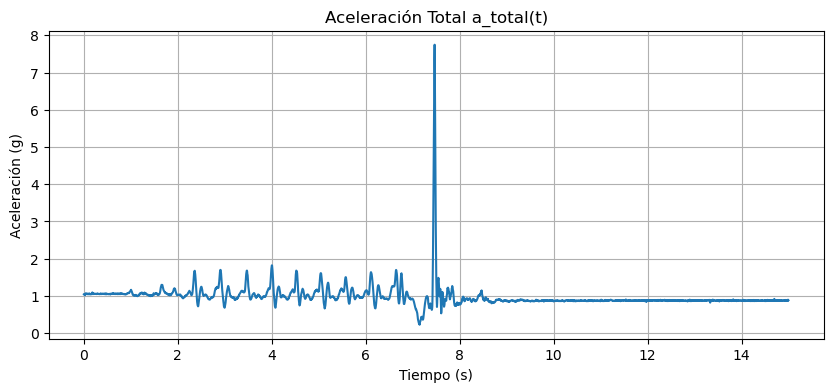

In [16]:
# 1. Factor de conversión del acelerómetro ADXL345 (según Readme: +-16g, 13 bits)
factor_g = (2 * 16) / (2**13)

# 2. Extraer columnas 0, 1 y 2 (X, Y, Z) y multiplicar por el factor
ax = datos_crudos[:, 0] * factor_g
ay = datos_crudos[:, 1] * factor_g
az = datos_crudos[:, 2] * factor_g

# 3. Calcular la magnitud de la aceleración total en cada instante t
a_total = np.sqrt(ax**2 + ay**2 + az**2)

# 4. Crear el vector de tiempo en segundos (frecuencia de muestreo = 200 Hz)

#Debido a que los archivos no nos dan los datos de los segundos, tenemos que construir el eje de tiempo a partir 
#de la cantidad de muestras y la frecuencia de muestreo. 
#La frecuencia de muestreo es de 200 Hz, es decir, 200 muestras por segundo. 
#Por lo tanto, el tiempo en segundos se puede calcular como el número de muestras dividido por la frecuencia de muestreo.
fs_muestreo = 200
tiempo = np.arange(len(a_total)) / fs_muestreo

# 5. Verificación visual en el dominio del tiempo
plt.figure(figsize=(10, 4))
plt.plot(tiempo, a_total)
plt.title("Aceleración Total a_total(t)")
plt.xlabel("Tiempo (s)")
plt.ylabel("Aceleración (g)")
plt.grid(True)
plt.show()

Ahora necesitamos eliminar la señal constante de la gravedad:
Para eso, primero calculamos el promedio aritmetico de toda la señal calculando un promedio de esta usando la funcion np.mean()
luego en cada muestra individual de a_total, es decir, las magnitudes en diferentes tiempo de la señal, se le resta el valor promedio hallado, que seria aproximadamente 1g correspondiente a la gravedad


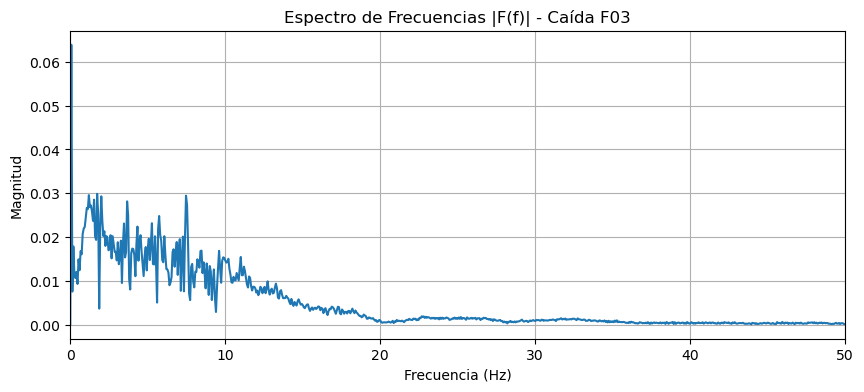

In [17]:
# 1. Quitar la componente constante de gravedad (0 Hz / DC)
a_sin_dc = a_total - np.mean(a_total)

# 2. Calcular la FFT para señales reales y su magnitud normalizada
N = len(a_sin_dc)
fft_compleja = np.fft.rfft(a_sin_dc)
magnitud = np.abs(fft_compleja) / N

# 3. Construir el eje X de frecuencias en Hz (sabemos que fs_muestreo = 200 Hz)
frecuencias = np.fft.rfftfreq(N, d=1 / fs_muestreo)

# 4. Graficar el espectro de frecuencias
plt.figure(figsize=(10, 4))
plt.plot(frecuencias, magnitud)
plt.title("Espectro de Frecuencias |F(f)| - Caída F03")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud")
plt.xlim(0, 50)  # Hacemos zoom de 0 a 50 Hz donde ocurre el movimiento humano
plt.grid(True)
plt.show()

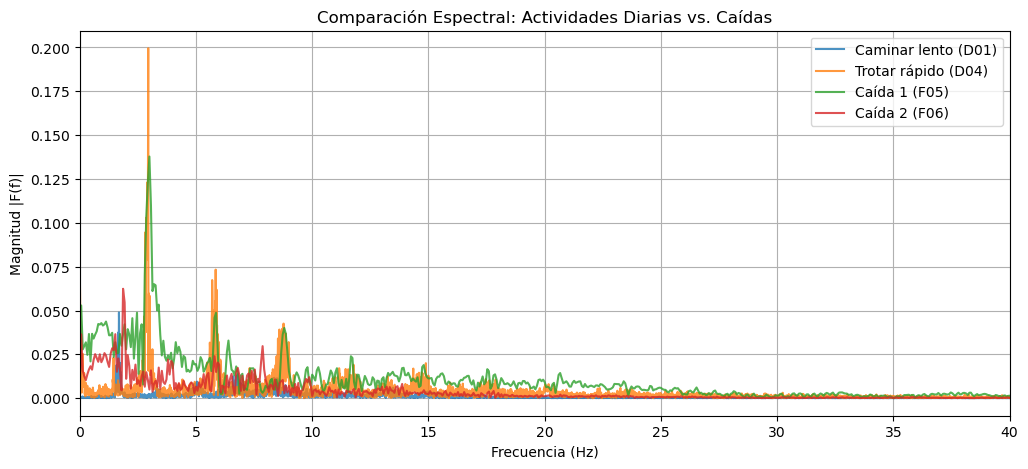

In [18]:
# 1. Creamos una función reutilizable que recibe la ruta de UN archivo y devuelve su FFT
def obtener_espectro(ruta):
  # Leer y limpiar los ';'
  with open(ruta, "r") as f:
    lineas = [linea.replace(";", "") for linea in f]
  datos = np.loadtxt(lineas, delimiter=",")

  # Convertir a g (ADXL345) y calcular magnitud total
  factor_g = (2 * 16) / (2**13)
  ax = datos[:, 0] * factor_g
  ay = datos[:, 1] * factor_g
  az = datos[:, 2] * factor_g
  a_total = np.sqrt(ax**2 + ay**2 + az**2)

  # Quitar gravedad constante (0 Hz) y calcular FFT normalizada
  a_sin_dc = a_total - np.mean(a_total)
  N = len(a_sin_dc)
  magnitud = np.abs(np.fft.rfft(a_sin_dc)) / N
  frecuencias = np.fft.rfftfreq(N, d=1 / 200)

  return frecuencias, magnitud


# 2. Diccionario con los 4 archivos clave de la Fase 1 (ajusta las rutas a tus carpetas)
archivos = {
    "Caminar lento (D01)": r"Archivos caídas/D01_SA01_R01.txt",
    "Trotar rápido (D04)": r"Archivos caídas/D04_SA03_R01.txt",
    "Caída 1 (F05)": r"Archivos caídas/F05_SA03_R01.txt",
    "Caída 2 (F06)": r"Archivos caídas/F06_SA03_R01.txt",
}

# 3. Graficar las 4 curvas superpuestas
plt.figure(figsize=(12, 5))

for etiqueta, ruta in archivos.items():
  freqs, mag = obtener_espectro(ruta)
  plt.plot(freqs, mag, label=etiqueta, alpha=0.8)

plt.title("Comparación Espectral: Actividades Diarias vs. Caídas")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud |F(f)|")
plt.xlim(0, 40)  # Zoom entre 0 y 40 Hz
plt.legend()
plt.grid(True)
plt.show()

### Importación de archivos como dataframes

In [19]:
import pandas as pd
from pathlib import Path

# Carpeta con los .txt (relativa a la carpeta del notebook/script: Proyecto_SisFall)
CARPETA = Path("Archivos caídas")

COLUMNAS = [
    'ADXL_X', 'ADXL_Y', 'ADXL_Z',  # Acelerómetro 1
    'ITG_X', 'ITG_Y', 'ITG_Z',     # Giroscopio
    'MMA_X', 'MMA_Y', 'MMA_Z'      # Acelerómetro 2
]

# Factores de conversión: (2 * Rango) / (2^Resolución)
FACTORES = {
    'ADXL': (2 * 16) / 2**13,    # ±16 g, 13 bits
    'ITG':  (2 * 2000) / 2**16,  # ±2000 °/s, 16 bits
    'MMA':  (2 * 8) / 2**14,     # ±8 g, 14 bits
}

def importar_y_limpiar(nombre_archivo, carpeta=CARPETA):
    """
    Importa un .txt de SisFall, lo limpia y lo convierte a unidades físicas.
    - nombre_archivo: con o sin extensión, ej. 'D04_SA01_R01' o 'D04_SA01_R01.txt'
    - Devuelve el DataFrame y además lo deja en memoria como df_<nombre>.
    """
    nombre = Path(nombre_archivo).stem
    ruta = Path(carpeta) / f"{nombre}.txt"

    # 1. Lectura
    df = pd.read_csv(ruta, sep=',', engine='python', header=None, names=COLUMNAS)

    # 2. Limpieza (el último dato de cada fila trae ';')
    df['MMA_Z'] = df['MMA_Z'].astype(str).str.replace(';', '').str.strip().astype(int)
    df = df.astype(int)

    # 3. Conversión de bits a valores físicos
    for prefijo, factor in FACTORES.items():
        cols = [f'{prefijo}_X', f'{prefijo}_Y', f'{prefijo}_Z']
        df[cols] = df[cols] * factor

    # 4. Guardar en memoria con el nombre df_<archivo>
    globals()[f"df_{nombre}"] = df
    print(f"✔ '{nombre}.txt' cargado → df_{nombre} ({df.shape[0]} filas)")
    return df

In [20]:
# Ejemplo de uso:

df_D04_SA01_R01 = importar_y_limpiar("D04_SA01_R01")
df_D04_SA01_R01.head()

✔ 'D04_SA01_R01.txt' cargado → df_D04_SA01_R01 (20000 filas)


,ADXL_X,ADXL_Y,ADXL_Z,ITG_X,ITG_Y,ITG_Z,MMA_X,MMA_Y,MMA_Z
0,0.375000,-1.605469,-0.410156,24.047852,30.761719,58.227539,0.344727,-1.586914,-0.291992
1,0.304688,-1.613281,-0.343750,5.737305,32.104492,61.096191,0.271484,-1.590820,-0.223633
2,0.218750,-1.671875,-0.238281,-7.751465,34.179688,64.758301,0.203125,-1.635742,-0.142578
3,0.089844,-1.691406,-0.128906,-14.587402,35.827637,64.514160,0.087891,-1.631836,-0.011719
4,-0.042969,-1.691406,0.003906,-14.465332,34.973145,63.476562,-0.026367,-1.631836,0.120117


### Función Graficar en Tiempo

In [21]:
import numpy as np
import plotly.graph_objects as go

FS = 200  # Frecuencia de muestreo (Hz)


def graficar_serie_tiempo(df, columna, actividad=None, fs=FS, color='royalblue', devolver=False):
    if columna not in df.columns:
        raise ValueError(f"'{columna}' no existe. Columnas disponibles: {list(df.columns)}")

    tiempo = np.arange(len(df)) / fs
    unidad_y = "Velocidad Angular (°/s)" if columna.startswith("ITG") else "Aceleración (g)"

    titulo = f"Serie de Tiempo: Sensor {columna}"
    if actividad:
        titulo += f" - {actividad}"

    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=tiempo,
        y=df[columna],
        mode='lines',
        name=columna,
        line=dict(width=2, color=color)
    ))

    fig.update_layout(
        title=titulo,
        xaxis_title="Tiempo (Segundos)",
        yaxis_title=unidad_y,
        template="plotly_white",
        hovermode="x unified"
    )

    fig.show()
    if devolver:
        return fig

In [22]:
graficar_serie_tiempo(df_D04_SA01_R01, 'ADXL_Y', actividad="Persona trotando suave")